In [19]:
import numpy as np
import xarray as xr
import zarr
import dask.array as dsa

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import cartopy.crs as ccrs
import cmocean
import seaborn as sns

from functools import partial

In [2]:
plt.style.use("../../nice.mplstyle")

In [3]:
def open_dataset(*args, **kwargs):
    xds = xr.open_dataset(*args, **kwargs)
    xds = xds.rename(
        {
            "values": "cell",
        }
    )
    xds["cell"] = np.arange(len(xds.cell))
    xds["elevation"] = xds.elevation.isel(time=0, drop=True)
    xds["land_fraction"] = xds.land_fraction.isel(time=0, drop=True)
    xds = xds.set_coords(["latitude", "longitude"])
    xds["mask"] = xds.land_fraction < 0.1
    return xds

In [45]:
from copy import deepcopy
def open_anemoi_zarr(path, array_name="data"):
    group = zarr.open(path, mode="r")
    if array_name == "data":
        da = xr.DataArray(
            dsa.from_zarr(group[array_name])[:, :, 0, :],
            dims=("time", "variable", "cell"),
            coords={
                "time": group["dates"][:],
                "variable": list(group.attrs["variables"]),
                "cell": np.arange(group["data"].shape[-1]),
                "latitude": ("cell", group["latitudes"][:]),
                "longitude": ("cell", group["longitudes"][:]),
            },
        )
    else:
        da = xr.DataArray(
            dsa.from_zarr(group[array_name]),
            dims=("variable",),
            coords={
                "variable": list(group.attrs["variables"]),
            },
        )
    xds = da.to_dataset(dim="variable")
    xds.attrs = deepcopy(group.attrs)
    return xds

In [37]:
ds = open_dataset("runs/no-removed-nodes/inference/2000-07-02T12.nc", chunks="auto")

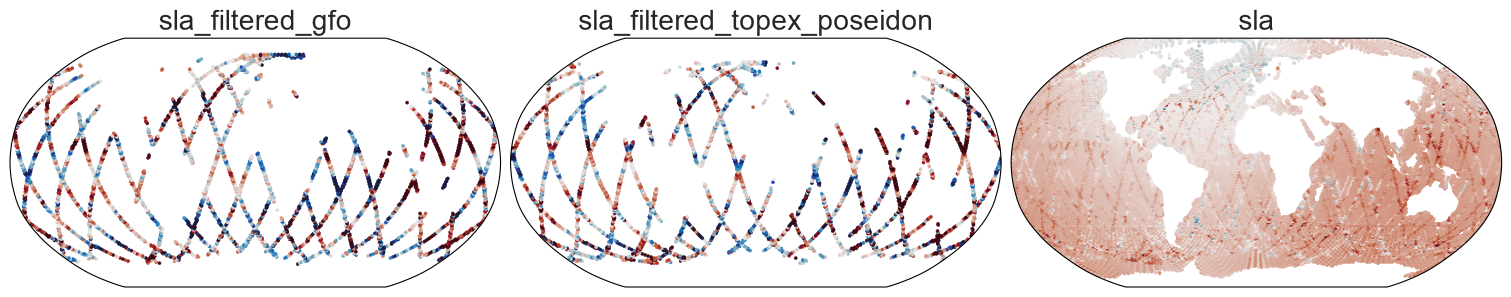

In [38]:
nrows = 1

varnames = [
    #"sla_filtered_ers_2",
    "sla_filtered_gfo",
    "sla_filtered_topex_poseidon",
    "sla",
]
ncols = len(varnames)

fig, axs = plt.subplots(nrows, ncols, figsize=(5*ncols, 4*nrows), subplot_kw={"projection": ccrs.Robinson()})

for varname, ax in zip(varnames, axs):
    itime = 0 if "filtered" in varname else 1
    ax.scatter(
        ds.longitude,
        ds.latitude,
        c=ds[varname].isel(time=itime).where(ds.mask).values,
        cmap="cmo.balance",
        vmin=-.1,
        vmax=.1,
        transform=ccrs.PlateCarree(),
        s=5,
    )
    ax.set(title=varname)

In [39]:
ads = open_anemoi_zarr("anemoi-hpx6-24h/dataset.zarr")

missions = [
    "sla_filtered_ers_2",
    "sla_filtered_gfo",
    "sla_filtered_topex_poseidon",
]

init_time, valid_time = ds.time.values
input_times = [init_time - np.timedelta64(24, "h"), init_time]

inputs = ads[missions].sel(time=input_times).compute()
inputs

<xarray.Dataset> Size: 2MB
Dimensions:                      (time: 2, cell: 49152)
Coordinates:
  * time                         (time) datetime64[s] 16B 2000-07-01T12:00:00...
  * cell                         (cell) int64 393kB 0 1 2 ... 49149 49150 49151
    latitude                     (cell) float64 393kB 0.5968 1.194 ... -0.5968
    longitude                    (cell) float64 393kB 45.0 45.7 ... 314.3 315.0
Data variables:
    sla_filtered_ers_2           (time, cell) float32 393kB nan nan ... nan nan
    sla_filtered_gfo             (time, cell) float32 393kB 0.005566 nan ... nan
    sla_filtered_topex_poseidon  (time, cell) float32 393kB nan nan ... nan nan
Attributes: (12/22)
    allow_nans:              True
    binned:                  True
    constant_fields:         []
    end_date:                2001-12-31T12:00:00
    ensemble_dimension:      1
    field_shape:             [49152]
    ...                      ...
    resolution:              healpix_6
    start_date:              2000-01-01T12:00:00
    time_bin_closed:         left
    time_bin_label:          middle
    variables:               ['sla_filtered_cryosat_2', 'sla_filtered_cryosat...
    variables_metadata:      {'sla_filtered_cryosat_2': {'group': 'cryosat_2'...

In [40]:
for varname in missions:
    same = np.array_equal(
        inputs[varname].sel(time=init_time).values,
        ds[varname].isel(time=0).values,
        equal_nan=True,
    )
    print(f"{varname}: matches inference file = {same}")

sla_filtered_ers_2: matches inference file = True
sla_filtered_gfo: matches inference file = True
sla_filtered_topex_poseidon: matches inference file = True


In [41]:
has_obs = inputs.notnull().any("time")
has_obs["any_mission"] = has_obs.to_dataarray(dim="variable").any("variable")

for varname in has_obs.data_vars:
    print(f"{varname}: {int(has_obs[varname].sum())} cells observed")

sla_filtered_ers_2: 0 cells observed
sla_filtered_gfo: 7242 cells observed
sla_filtered_topex_poseidon: 7061 cells observed
any_mission: 12647 cells observed


[Text(0.5, 1.0, 'observed in inputs (2000-07-01T12, 2000-07-02T12)\nfor forecast valid 2000-07-03T12')]

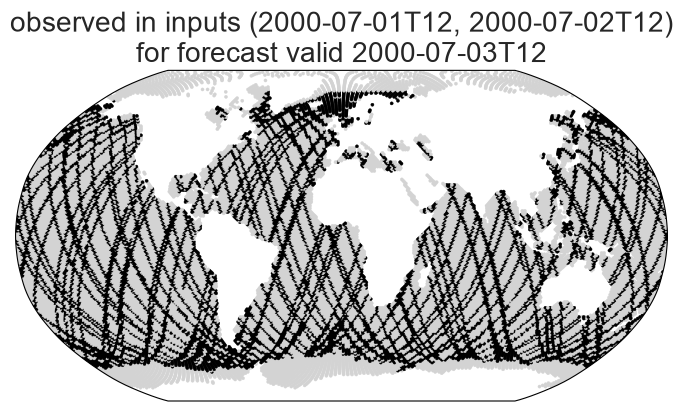

In [42]:
fig, ax = plt.subplots(figsize=(7, 4), subplot_kw={"projection": ccrs.Robinson()})
ax.scatter(
    ads.longitude,
    ads.latitude,
    c=has_obs.any_mission.where(ds.mask).values,
    cmap=ListedColormap(["lightgray", "black"]),
    vmin=0,
    vmax=1,
    transform=ccrs.PlateCarree(),
    s=5,
)
ax.set(
    title=f"observed in inputs ({str(input_times[0])[:13]}, {str(input_times[1])[:13]})"
    f"\nfor forecast valid {str(valid_time)[:13]}"
)

In [46]:
avg = open_anemoi_zarr("anemoi-hpx6-24h/dataset.zarr", array_name="mean")
std = open_anemoi_zarr("anemoi-hpx6-24h/dataset.zarr", array_name="stdev")

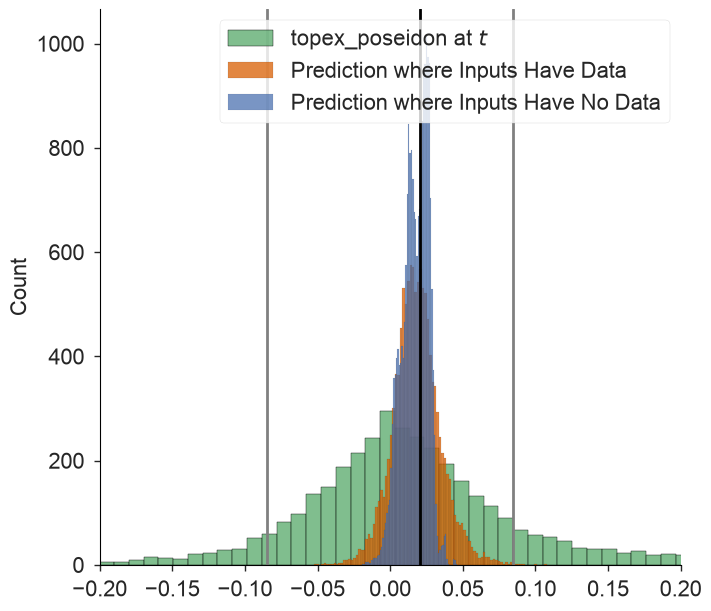

In [58]:
fig, ax = plt.subplots()
for mission in ["topex_poseidon"]:
    xda = ds[f"sla_filtered_{mission}"].isel(time=0)
    sns.histplot(
        xda.where(~np.isnan(xda)),
        ax=ax,
        label=f"{mission} at $t$"
    )
for ff, lbl in zip(
    [has_obs["any_mission"], ~has_obs["any_mission"]],
    ["Inputs Have Data", "Inputs Have No Data"],
):
    sns.histplot(
        ds["sla"].isel(time=1).where(ds["mask"]).where(ff),
        ax=ax,
        label=f"Prediction where {lbl}",
    ) 
ax.axvline(x=avg["sla_filtered_topex_poseidon"], color="black")
ax.axvline(x=std["sla_filtered_topex_poseidon"], color="gray")
ax.axvline(x=-std["sla_filtered_topex_poseidon"], color="gray")
ax.set(xlim=[-.2, .2])
ax.legend()